# Temporal Graph Neural Networks for Risk Detection Under Distribution Shift
## 01 · Data exploration and research foundation

**Research question:** Does graph-based learning improve future-period illicit Bitcoin transaction detection relative to strong tabular models, especially under temporal distribution shift?

This notebook validates the **original Elliptic** release, describes its labeled population and graph, fixes chronological partitions, and audits information availability. It does not train predictive models or establish deployment performance.

**Read before running:** Published features have unresolved point-in-time provenance. Chronological splitting and train-only preprocessing cannot repair contaminated source features. We distinguish **A: published-feature benchmark**, **B: conservative feature sensitivities**, and **C: claims the release cannot establish**.

**Interface:** Edit the configuration cell, feature lists and plotting code directly. Helpers contain only repeated data, protocol and environment checks. All data checks run in both modes; QUICK_RUN samples only expensive diagnostic plots and is exploratory.

1. [Introduction](#1-introduction)
2. [Dataset overview](#2-dataset-overview)
3. [Loading and validation](#3-loading-and-validation)
4. [Label analysis](#4-label-analysis)
5. [Feature analysis](#5-feature-analysis)
6. [Graph structure](#6-graph-structure)
7. [Temporal patterns](#7-temporal-patterns)
8. [Chronological split](#8-chronological-split)
9. [Leakage audit](#9-leakage-audit)
10. [Key findings](#10-key-findings)

<a id="1-introduction"></a>
## 1. Introduction

The estimand is illicit-vs-licit classification **conditional on having a known label**. Unknown nodes are excluded from supervised losses and metrics, but may contribute eligible graph structure. Label selection is not random; results cannot be extrapolated to all Bitcoin activity.

At the end of snapshot $t$, predict its eligible transactions using information available by $t$. Future snapshot nodes, edges and labels are forbidden. This is an information boundary on our constructed inputs, not certification of the published features.

Stage 1 shows test-period label summaries as explicitly requested. They are descriptive only. Feature/label comparison plots use training data. Later stages must freeze feature groups, models, thresholds, calibration and evaluation rules using steps 1–34 before final testing. The label-access guard is procedural: public benchmark labels are not cryptographically hidden.

In [1]:
from pathlib import Path
import os
import sys
import json
import time
import random

# Launch from the repository root or notebooks/; no machine-specific path.
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file():
    raise RuntimeError("Launch Jupyter from the repository root or notebooks/.")
sys.path.insert(0, str(ROOT))

RUN_MODE = "FULL_RUN"  # "QUICK_RUN" is exploratory; neither mode trains models here.
if RUN_MODE not in {"QUICK_RUN", "FULL_RUN"}:
    raise ValueError("Choose QUICK_RUN or FULL_RUN")
QUICK_RUN = RUN_MODE == "QUICK_RUN"
SEED = 42
DATA_DIR = Path(os.environ.get("ELLIPTIC_DATA_DIR", "data/raw"))
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
FIGURE_DIR = ROOT / "reports" / "figures"
RESULT_DIR = ROOT / "results"
PROCESSED_DIR = ROOT / "data" / "processed"
PLOT_SAMPLE = 8_000 if QUICK_RUN else 40_000
CORRELATION_SAMPLE = 10_000 if QUICK_RUN else None

# Keep library caches writable and out of Git.
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
started_at = time.perf_counter()
random.seed(SEED)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import networkx as nx
import scipy.sparse as sparse
from scipy.sparse.csgraph import connected_components
from IPython.display import display, Markdown
import torch

from src.data import (FEATURE_COLUMNS, EXPECTED_COUNTS, load_elliptic, feature_groups,
                      file_fingerprints, snapshot_summary)
from src.protocol import (SPLIT_RANGES, chronological_partitions, save_split_definitions,
                          graph_at_step, supervised_targets)
from src.environment import compatibility_report

np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "svg.fonttype": "none"})
COLORS = {"licit": "#0072B2", "illicit": "#D55E00", "unknown": "#999999"}
SPLIT_COLORS = {"train": "#0072B2", "validation": "#009E73", "test": "#CC79A7"}
figure_names = []

def save_figure(figure, name):
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    figure_names.append(name)
    plt.show()
    plt.close(figure)

print(f"Mode: {RUN_MODE}; exploratory={QUICK_RUN}. Full population validation is always enabled.")

Mode: FULL_RUN; exploratory=False. Full population validation is always enabled.


### Environment and hardware

Each operation below runs a forward pass, backward pass and one optimizer update. MPS outputs and input gradients are checked against CPU within stated tolerances. Native CPU LightGBM is fitted on a tiny artificial smoke-test matrix, which is unrelated to research data or results. Unsupported MPS operations are recorded and assigned CPU explicitly. Dense COO edge-index smoke tests do not certify sparse layouts, samplers, larger graphs or exact reproducibility across devices.

In [2]:
environment = compatibility_report()
(RESULT_DIR / "environment.json").write_text(json.dumps(environment, indent=2) + "\n")
display(pd.Series({key: environment[key] for key in ["python", "system", "architecture", "macos",
                     "mps_built", "mps_available", "implicit_mps_fallback"]}, name="observed"))
display(pd.DataFrame(environment["operations"]))
display(pd.Series(environment["versions"], name="version").to_frame())
print("LightGBM:", environment["lightgbm_native_fit"])

python                   3.11.1
system                   Darwin
architecture              arm64
macos                      15.3
mps_built                  True
mps_available              True
implicit_mps_fallback         0
Name: observed, dtype: object

,operation,device,status,seconds
0,dense_linear,cpu,passed,0.0087
1,dense_linear,mps,passed,0.1011
2,SAGEConv_mean,cpu,passed,0.0034
3,SAGEConv_mean,mps,passed,0.0258
4,GATConv,cpu,passed,0.0061
5,GATConv,mps,passed,0.0788


,version
torch,2.8.0
torch-geometric,2.7.0
numpy,2.2.6
pandas,2.3.3
scipy,1.16.3
scikit-learn,1.7.2
lightgbm,4.6.0
matplotlib,3.10.7
seaborn,0.13.2
networkx,3.5


LightGBM: passed_on_synthetic_smoke_data_not_a_research_result


<a id="2-dataset-overview"></a>
## 2. Dataset overview

Source: [original Elliptic Kaggle dataset](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set), introduced by [Weber et al. (2019)](https://arxiv.org/abs/1908.02591). This is not Elliptic++ or Elliptic2.

Download manually, unzip, and place the three CSVs in `data/raw/`, or set `ELLIPTIC_DATA_DIR` before launching Jupyter. The features CSV has **no header**; class and edge CSVs have headers. Full installation and download instructions are in the README.

Kaggle's source metadata identifies **CC BY-NC-ND 4.0** (checked 2026-11-08). Project MIT licensing covers original code only. Raw data, per-node splits, predictions, and other derived transaction-level files remain local and ignored. Figures and aggregate research summaries are separate from redistributing a dataset; review current source terms before publication.

Time steps are ordered observation windows, approximately two weeks apart, rather than continuous coverage of all Bitcoin activity. Calendar dates and per-edge arrival times are absent. The following counts are expectations to verify, not measurements until the loading cell succeeds.

In [3]:
display(pd.Series(EXPECTED_COUNTS, name="expected_original_release").to_frame())
group_mapping = pd.DataFrame([
    ["time", "time_step", "1", "1", 1],
    ["other local", "feature_002 … feature_094", "2–94", "2–94", 93],
    ["neighborhood aggregates", "feature_095 … feature_166", "95–166", "95–166", 72],
], columns=["group", "internal_columns", "published_feature_number", "zero_based_csv_column", "count"])
display(group_mapping)

,expected_original_release
transactions,203769
edges,234355
time_steps,49
illicit,4545
licit,42019
unknown,157205


,group,internal_columns,published_feature_number,zero_based_csv_column,count
0,time,time_step,1,1,1
1,other local,feature_002 … feature_094,2–94,2–94,93
2,neighborhood aggregates,feature_095 … feature_166,95–166,95–166,72


<a id="3-loading-and-validation"></a>
## 3. Loading and validation

Column 0 is the transaction ID; column 1 is time; columns 2–166 are other features. This positional convention is cross-checked against [PyG's original-dataset loader](https://pytorch-geometric.readthedocs.io/en/latest/_modules/torch_geometric/datasets/elliptic.html) and the [authors' semantics documentation](https://github.com/nesfit/DeanonymizedEllipticBitcoinDataset). CSV dimensions and time are verified programmatically; opaque numeric values alone cannot prove every semantic interpretation.

We preserve IDs as strings and create a stable index by lexicographic ID order. Labels are joined one-to-one by ID, never attached by row position. Duplicate IDs, duplicate edges, unrecognized labels, invalid timestamps and endpoints fail explicitly. Missing or non-finite numeric features (NaN and positive or negative infinity), including time, stop loading with counts and affected column names. No rows are dropped, values imputed, or source CSVs modified. Unknown targets remain intentionally missing and are not subject to this feature-value check. IDs and transaction-level rows are not displayed.

In [4]:
load_started = time.perf_counter()
nodes, edges, diagnostics = load_elliptic(DATA_DIR, verify_original=True)
raw_hashes = file_fingerprints(DATA_DIR)
load_seconds = time.perf_counter() - load_started
snapshots = snapshot_summary(nodes, edges)
partitions = chronological_partitions(nodes)
training_nodes = nodes.loc[partitions == "train"].copy()
known_training = training_nodes.loc[training_nodes.target.notna()].copy()

display(pd.Series(diagnostics, name="observed").to_frame())
print(f"Validated and fingerprinted in {load_seconds:.2f} seconds.")
print("Target dtype:", nodes.target.dtype, "| Unknown targets stay missing:", nodes.target.isna().sum())
print("Index alignment:", np.array_equal(nodes.node_index.to_numpy(), np.arange(len(nodes))))
quality_table = pd.DataFrame({
    "check": ["Missing feature values", "Non-finite feature values (including missing)", "Duplicate feature records", "Duplicate class records",
              "Duplicate edges", "Duplicate feature vectors (distinct IDs)", "Self loops", "Cross-time edges"],
    "count": [diagnostics[key] for key in ["missing_feature_values", "non_finite_feature_values", "duplicate_feature_records",
             "duplicate_class_records", "duplicate_edges", "duplicate_feature_vectors", "self_loops", "cross_time_edges"]],
})
display(quality_table)
missing_by_feature = nodes[FEATURE_COLUMNS].isna().sum().rename("missing_count")
display(missing_by_feature.sort_values(ascending=False).head(8).to_frame())
(RESULT_DIR / "data_validation.json").write_text(json.dumps(diagnostics, indent=2) + "\n")

,observed
transactions,203769.000000
edges,234355.000000
time_steps,49.000000
illicit,4545.000000
licit,42019.000000
unknown,157205.000000
published_features_including_time,166.000000
missing_feature_values,0.000000
non_finite_feature_values,0.000000
duplicate_feature_records,0.000000


Validated and fingerprinted in 4.21 seconds.
Target dtype: Int8 | Unknown targets stay missing: 157205
Index alignment: True


,check,count
0,Missing feature values,0
1,Non-finite feature values (including missing),0
2,Duplicate feature records,0
3,Duplicate class records,0
4,Duplicate edges,0
5,Duplicate feature vectors (distinct IDs),34
6,Self loops,0
7,Cross-time edges,0


,missing_count
time_step,0
feature_105,0
feature_107,0
feature_108,0
feature_109,0
feature_110,0
feature_111,0
feature_112,0


475

**Interpretation:** Distinct IDs with identical feature vectors remain distinct graph nodes. Removing them would alter the benchmark population and graph. Zero missing values or invalid edges establish file integrity, not freedom from source-level leakage. Hashes identify the local input bytes without exposing IDs or local paths.

<a id="4-label-analysis"></a>
## 4. Label analysis

Original class `1` becomes illicit **1**, class `2` becomes licit **0**, and `unknown` becomes missing. The supervised denominator is $n_{illicit}+n_{licit}$, not all transactions. With rare positives, Average Precision (AP) will be the primary metric in later stages; trapezoidal PR area is a different statistic and will not be substituted silently.

,transactions,percentage_all_transactions
class_name,,
licit,42019,20.620899
illicit,4545,2.230467
unknown,157205,77.148634


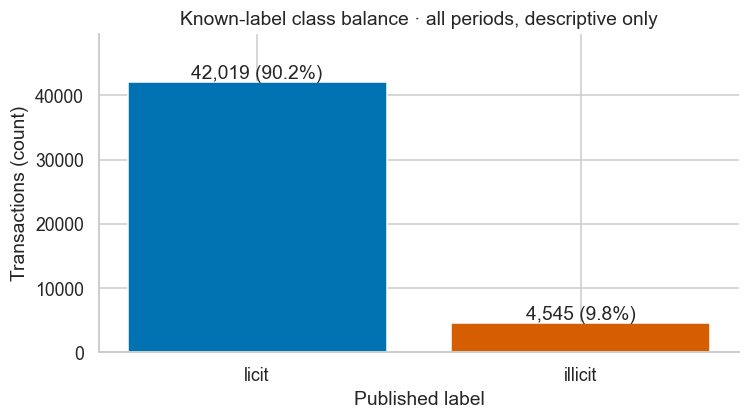

In [5]:
class_counts = nodes.class_name.value_counts().reindex(["licit", "illicit", "unknown"])
label_table = class_counts.rename("transactions").to_frame()
label_table["percentage_all_transactions"] = 100 * label_table.transactions / len(nodes)
display(label_table)

fig, ax = plt.subplots(figsize=(7, 4))
labeled_counts = class_counts.loc[["licit", "illicit"]]
ax.bar(labeled_counts.index, labeled_counts.values, color=[COLORS[key] for key in labeled_counts.index])
for position, value in enumerate(labeled_counts):
    ax.text(position, value, f"{value:,} ({value / labeled_counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Known-label class balance · all periods, descriptive only", xlabel="Published label", ylabel="Transactions (count)")
ax.set_ylim(0, labeled_counts.max() * 1.18)
save_figure(fig, "01_labeled_class_balance")

**Interpretation:** The labeled class proportions describe the evaluation population. Unknown is a label-availability category, not a third supervised class and not evidence of licitness. Because known labels are selected, even a well-calibrated score among known labels need not be calibrated for unknown transactions.

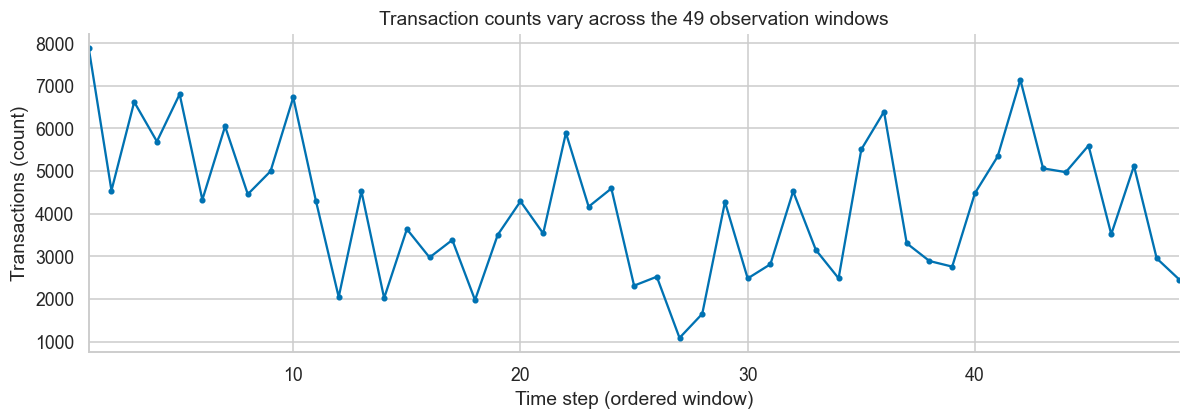

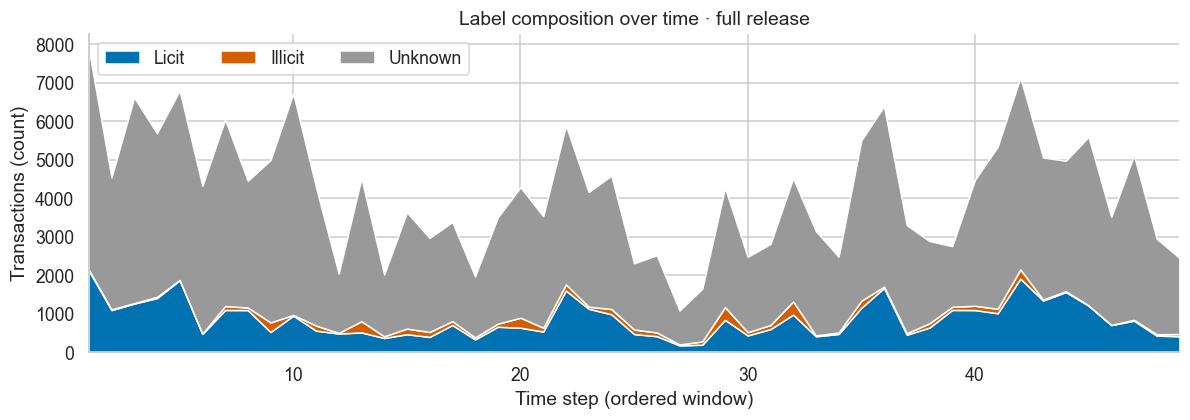

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(snapshots.index, snapshots.transactions, color=COLORS["licit"], marker=".", linewidth=1.5)
ax.set(title="Transaction counts vary across the 49 observation windows", xlabel="Time step (ordered window)", ylabel="Transactions (count)")
ax.set_xlim(1, 49)
save_figure(fig, "02_transactions_over_time")

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(snapshots.index, *[snapshots[key] for key in ["licit", "illicit", "unknown"]],
             labels=["Licit", "Illicit", "Unknown"], colors=[COLORS[key] for key in ["licit", "illicit", "unknown"]])
ax.set(title="Label composition over time · full release", xlabel="Time step (ordered window)", ylabel="Transactions (count)")
ax.legend(loc="upper left", ncol=3)
ax.set_xlim(1, 49)
save_figure(fig, "03_classes_over_time")

**Interpretation:** Unequal snapshot sizes affect pooled metrics: large periods receive more weight. Later evaluation should report pooled AP together with per-period results, class counts, and label coverage. Counts alone do not identify concept drift or changes in criminal activity.

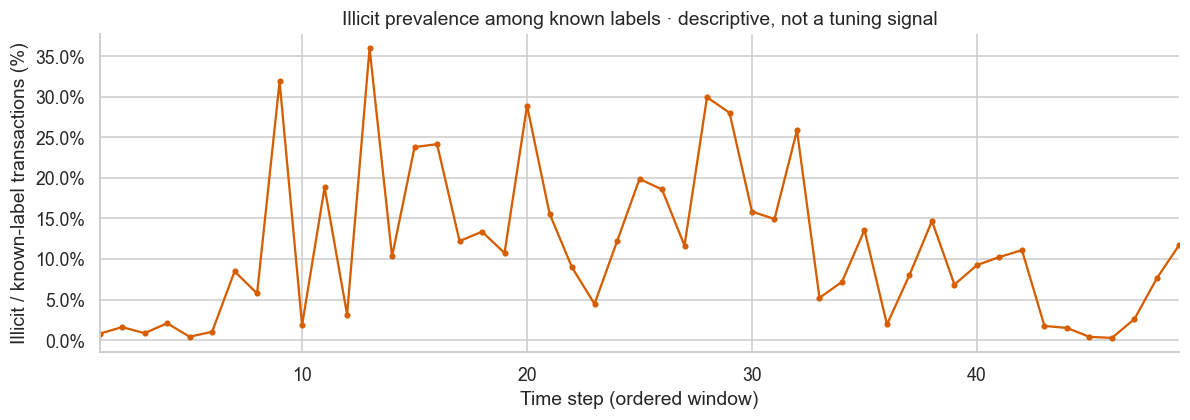

class_name,licit,illicit,unknown,labeled,illicit_prevalence
count,49.000,49.000,49.000,49.000,49.000
mean,857.531,92.755,3208.265,950.286,0.113
std,477.005,86.836,1203.592,479.875,0.095
min,182.000,2.000,883.000,206.000,0.003
25%,476.000,24.000,2135.000,524.000,0.026
50%,710.000,80.000,3202.000,811.000,0.102
75%,1102.000,118.000,4166.000,1211.000,0.156
max,2130.000,342.000,5755.000,2154.000,0.360


In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(snapshots.index, snapshots.illicit_prevalence, marker="o", markersize=3, color=COLORS["illicit"])
ax.yaxis.set_major_formatter(ticker.PercentFormatter(1))
ax.set(title="Illicit prevalence among known labels · descriptive, not a tuning signal", xlabel="Time step (ordered window)", ylabel="Illicit / known-label transactions (%)")
ax.set_xlim(1, 49)
save_figure(fig, "04_illicit_prevalence")
display(snapshots[["licit", "illicit", "unknown", "labeled", "illicit_prevalence"]].describe().round(3))

**Interpretation:** Changes in labeled prevalence can change AP even when ranking quality is unchanged. Small positive counts make period-level estimates unstable. These are finite-dataset descriptive rates; binomial confidence bands would imply independent random label sampling that this graph benchmark does not justify.

<a id="5-feature-analysis"></a>
## 5. Feature analysis

The next comparisons use **training periods 1–29 only**. Selected feature numbers are fixed for interpretability across groups rather than selected for high label association. Values are published normalized units, not recoverable BTC or counts. We retain positional names because recovered semantics are independent research claims.

Three matching feature configurations are defined for later tabular and graph comparisons:

| Configuration | Helper key | Published feature numbers | Count |
|---|---|---|---:|
| Conservative transaction features | `transaction_sensitivity` | 2–22 except unresolved 4, 8 and 16 | 18 |
| Published local features, excluding time | `local_without_time` | 2–94 | 93 |
| Published non-time features | `published_without_time` | 2–166 | 165 |

**None of the three configurations is certified leakage-free.** Excluding neighborhood aggregates still leaves address-history features 23–94 in the local group. The 18-feature subset is a conservative sensitivity analysis, not a certified clean dataset. The address-history and neighborhood lists in the helper support the audit.

Compare tabular and graph models on the same feature columns and order, labeled evaluation nodes, and chronological information boundary: 18 against 18, 93 against 93, and 165 against 165. Differences across feature groups are sensitivity comparisons and must not be attributed solely to model architecture.

In [8]:
groups = feature_groups()
selected_features = ["feature_002", "feature_003", "feature_005", "feature_006", "feature_023", "feature_095"]
feature_statistics = training_nodes[groups["published_without_time"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
feature_statistics["missing"] = training_nodes[groups["published_without_time"]].isna().sum()
feature_statistics["distinct_values"] = training_nodes[groups["published_without_time"]].nunique()
display(feature_statistics.loc[selected_features].round(3))
print("Training-constant non-time features:", int((feature_statistics.distinct_values <= 1).sum()))
print("Negative values are allowed because published features are normalized.")

# IQR flags diagnose tails; they do not define errors or justify deleting rows.
q1 = training_nodes[selected_features].quantile(0.25)
q3 = training_nodes[selected_features].quantile(0.75)
iqr = q3 - q1
outside = ((training_nodes[selected_features] < q1 - 1.5 * iqr)
           | (training_nodes[selected_features] > q3 + 1.5 * iqr)).mean()
display((100 * outside).rename("outside_training_1.5_IQR_percent").to_frame().round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing,distinct_values
feature_002,120804.0,0.026,1.035,-0.173,-0.173,-0.172,-0.169,-0.134,2.963,46.390,0,115536
feature_003,120804.0,-0.130,0.300,-0.211,-0.199,-0.185,-0.172,-0.133,0.317,25.674,0,12456
feature_005,120804.0,-0.001,0.989,-0.122,-0.122,-0.122,-0.122,-0.047,1.679,49.028,0,250
feature_006,120804.0,0.002,1.166,-0.064,-0.064,-0.044,-0.044,-0.044,0.333,260.091,0,207
feature_023,120804.0,0.009,1.119,-0.140,-0.140,-0.140,-0.140,-0.140,5.189,25.474,0,83785
feature_095,120804.0,-0.006,0.803,-0.171,-0.171,-0.171,-0.167,-0.129,2.451,39.385,0,105842


Training-constant non-time features: 0
Negative values are allowed because published features are normalized.


,outside_training_1.5_IQR_percent
feature_002,18.26
feature_003,7.73
feature_005,8.96
feature_006,21.27
feature_023,18.63
feature_095,18.05


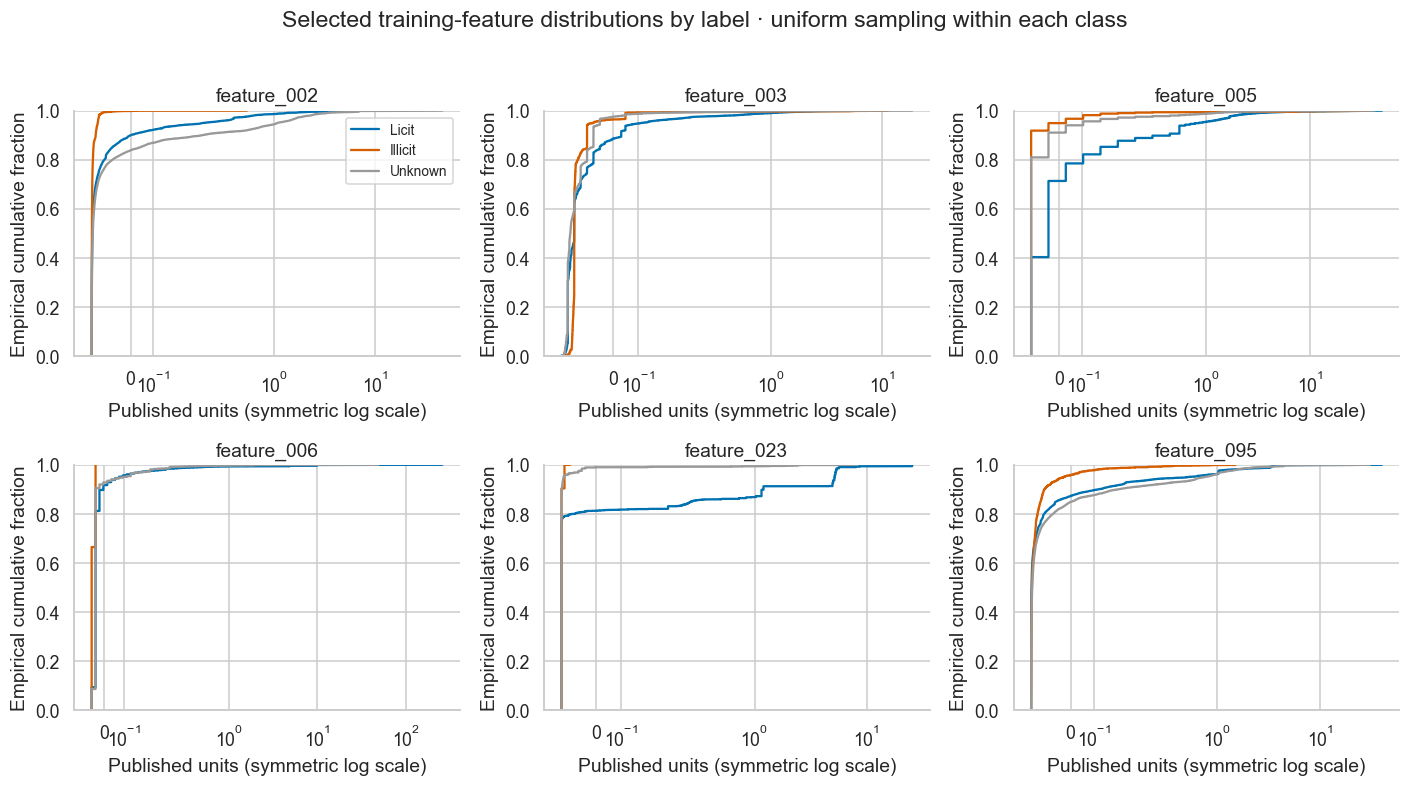

In [9]:
# Independent uniform samples within each training label group, fixed seed.
plot_rows = pd.concat([frame.sample(n=min(len(frame), PLOT_SAMPLE), random_state=SEED)
                      for _, frame in training_nodes.groupby("class_name", sort=True)])
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, selected_features):
    for class_name in ["licit", "illicit", "unknown"]:
        values = plot_rows.loc[plot_rows.class_name == class_name, feature]
        sns.ecdfplot(x=values, ax=ax, label=class_name.title(), color=COLORS[class_name])
    ax.set_xscale("symlog", linthresh=0.5)
    ax.set(title=feature, xlabel="Published units (symmetric log scale)", ylabel="Empirical cumulative fraction")
axes[0, 0].legend(fontsize=9)
fig.suptitle("Selected training-feature distributions by label · uniform sampling within each class", y=1.02)
save_figure(fig, "05_training_feature_distributions")

**Interpretation:** ECDF curves show distributional differences without KDE bandwidth choices. Per-class samples support shape comparisons; they do not preserve the population class proportions. Heavy tails are plausible in transaction features. Observed association is neither causal evidence nor an estimate of future model performance.

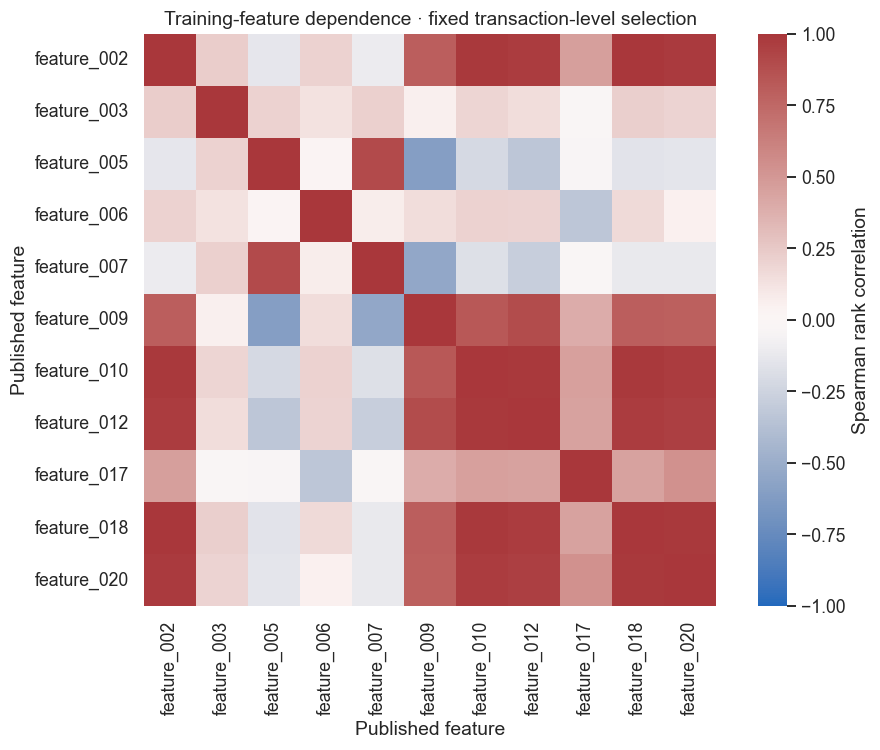

In [10]:
correlation_rows = training_nodes
if CORRELATION_SAMPLE is not None:
    correlation_rows = training_nodes.sample(n=min(len(training_nodes), CORRELATION_SAMPLE), random_state=SEED)
correlation_features = ["feature_002", "feature_003", "feature_005", "feature_006", "feature_007",
                        "feature_009", "feature_010", "feature_012", "feature_017", "feature_018", "feature_020"]
correlation = correlation_rows[correlation_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            ax=ax, cbar_kws={"label": "Spearman rank correlation"})
ax.set(title="Training-feature dependence · fixed transaction-level selection", xlabel="Published feature", ylabel="Published feature")
save_figure(fig, "06_training_feature_correlation")

**Interpretation:** Correlated features can make coefficient and feature-importance interpretations unstable. This fixed diagnostic is not a feature-selection procedure. Scaling, imputation and any learned selection will be fitted exclusively on training data in later stages.

<a id="6-graph-structure"></a>
## 6. Graph structure

Transactions are nodes; published directed edges represent payment flow. All nodes, including unknown labels, are retained. Full-release degrees below are **EDA statistics**, not precomputed inputs for earlier predictions. Any structural features used later must be recomputed inside the prediction cutoff.

,in_degree,out_degree
count,203769.000,203769.000
mean,1.150,1.150
std,3.911,1.895
min,0.000,0.000
50%,1.000,1.000
90%,1.000,2.000
99%,9.000,5.000
max,284.000,472.000


Isolates: 0


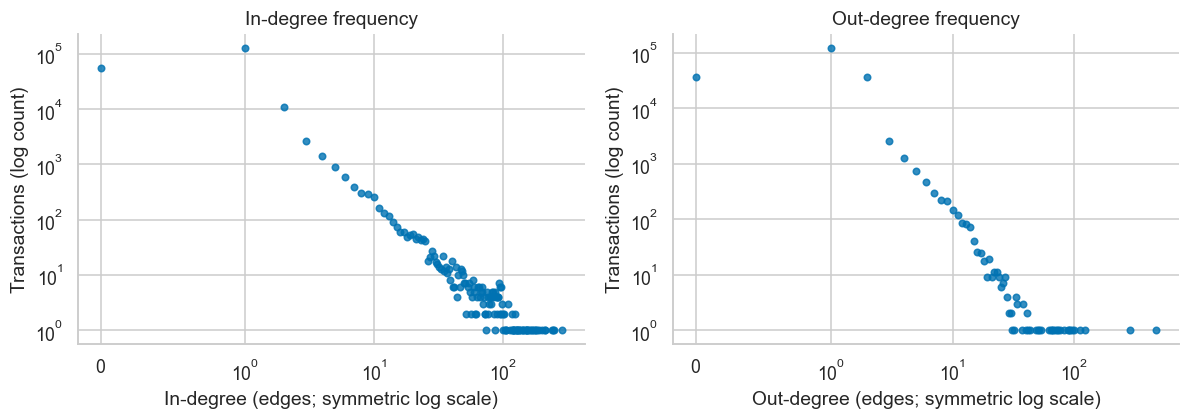

In [11]:
in_degree = np.bincount(edges.target.to_numpy(), minlength=len(nodes))
out_degree = np.bincount(edges.source.to_numpy(), minlength=len(nodes))
degree_table = pd.DataFrame({"in_degree": in_degree, "out_degree": out_degree})
display(degree_table.describe(percentiles=[0.5, 0.9, 0.99]).round(3))
print("Isolates:", int(((in_degree + out_degree) == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, label in zip(axes, [in_degree, out_degree], ["In-degree", "Out-degree"]):
    frequency = pd.Series(values).value_counts().sort_index()
    ax.scatter(frequency.index, frequency.values, s=18, color=COLORS["licit"], alpha=0.8)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("log")
    ax.set(title=f"{label} frequency", xlabel=f"{label} (edges; symmetric log scale)", ylabel="Transactions (log count)")
save_figure(fig, "07_degree_distributions")

**Interpretation:** Zero degrees remain visible on the symmetric log x-axis; log y emphasizes the tail. High-degree nodes can dominate aggregation and computational cost. This view does not establish a power law, liquidity, or whether a transaction is illicit.

,observed
weak_components,49.000000
strong_components,203769.000000
largest_weak_component_nodes,7880.000000
largest_weak_component_share,0.038671
isolates,0.000000


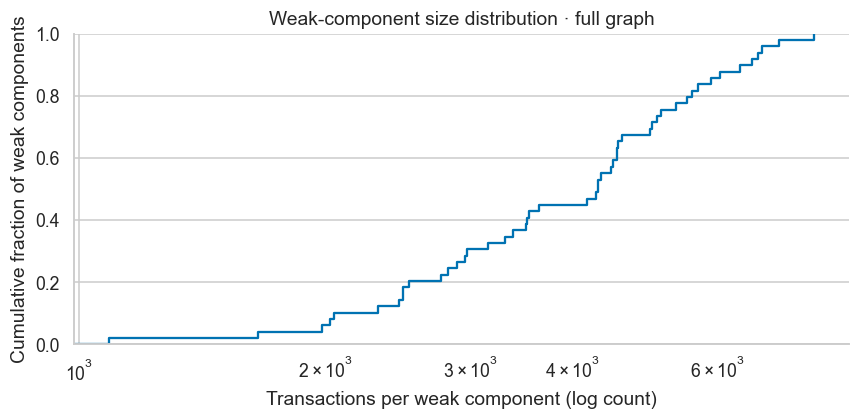

In [12]:
adjacency = sparse.coo_matrix((np.ones(len(edges), dtype=np.int8),
                              (edges.source.to_numpy(), edges.target.to_numpy())),
                             shape=(len(nodes), len(nodes))).tocsr()
weak_count, weak_labels = connected_components(adjacency, directed=True, connection="weak")
strong_count, strong_labels = connected_components(adjacency, directed=True, connection="strong")
component_sizes = np.bincount(weak_labels)
component_summary = {
    "weak_components": int(weak_count), "strong_components": int(strong_count),
    "largest_weak_component_nodes": int(component_sizes.max()),
    "largest_weak_component_share": float(component_sizes.max() / len(nodes)),
    "isolates": int(((in_degree + out_degree) == 0).sum()),
}
display(pd.Series(component_summary, name="observed").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(x=component_sizes, ax=ax, color=COLORS["licit"])
ax.set_xscale("log")
ax.set(title="Weak-component size distribution · full graph", xlabel="Transactions per weak component (log count)", ylabel="Cumulative fraction of weak components")
save_figure(fig, "08_weak_component_sizes")

**Interpretation:** Weak connectivity ignores edge direction; strong connectivity requires directed reachability. A directed transaction graph need not be strongly connected. Component membership is not an entity label: disconnected transactions may share addresses or other source-level information outside the released edge list.

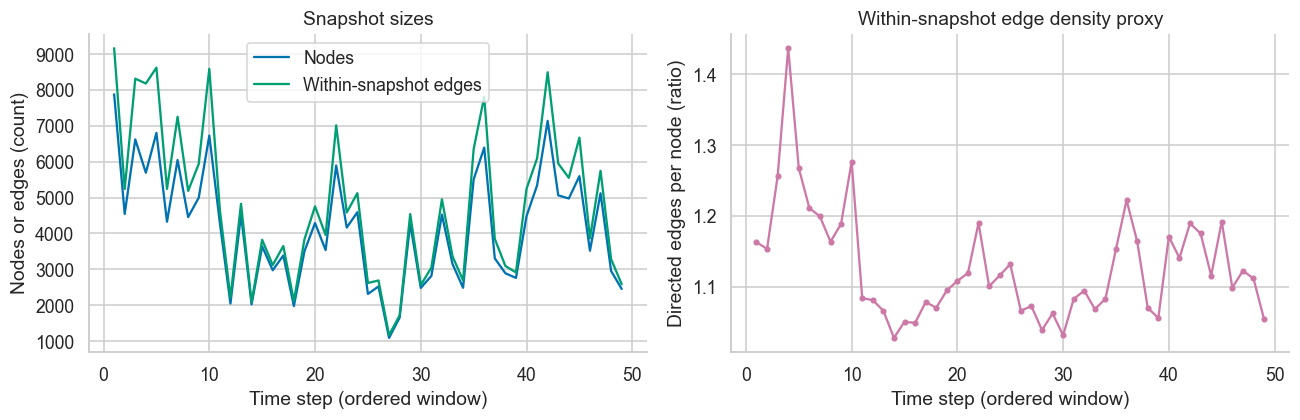

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(snapshots.index, snapshots.transactions, label="Nodes", color=COLORS["licit"])
axes[0].plot(snapshots.index, snapshots.within_snapshot_edges, label="Within-snapshot edges", color="#009E73")
axes[0].set(title="Snapshot sizes", xlabel="Time step (ordered window)", ylabel="Nodes or edges (count)")
axes[0].legend()
axes[1].plot(snapshots.index, snapshots.within_edges_per_node, color="#CC79A7", marker=".")
axes[1].set(title="Within-snapshot edge density proxy", xlabel="Time step (ordered window)", ylabel="Directed edges per node (ratio)")
save_figure(fig, "09_snapshot_graph_statistics")

**Interpretation:** Edges per node is a sparse-graph size ratio, not the conventional density $m/[n(n-1)]$. Node counts, edge counts and topology can change independently. Cross-time edges, if present, are counted separately and become eligible only when both endpoints are available.

The transaction-level graph illustration is omitted from this public package. The preceding aggregate plots describe the released graph.

<a id="7-temporal-patterns"></a>
## 7. Temporal patterns

These fixed descriptive diagnostics assess coverage and changing feature distributions. They do not test causality or establish a specific drift mechanism. We do not use test-period labels to choose features, models or thresholds.

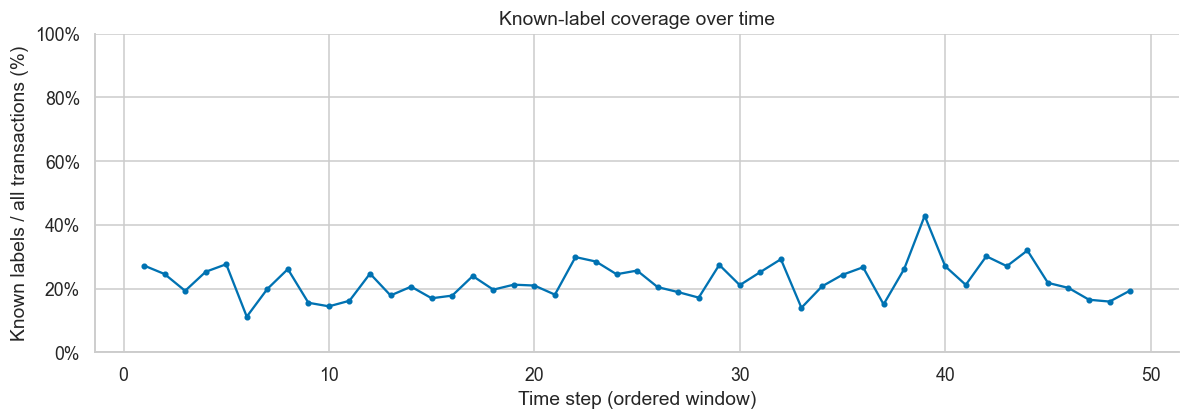

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(snapshots.index, snapshots.label_coverage, color=COLORS["licit"], marker=".")
ax.yaxis.set_major_formatter(ticker.PercentFormatter(1))
ax.set(title="Known-label coverage over time", xlabel="Time step (ordered window)", ylabel="Known labels / all transactions (%)", ylim=(0, 1))
save_figure(fig, "11_label_coverage")

**Interpretation:** Varying coverage is evidence that the measured labeled population changes. It does not reveal the true illicit rate among unknown nodes. Later results must always report the common labeled evaluation population and positive count alongside metrics.

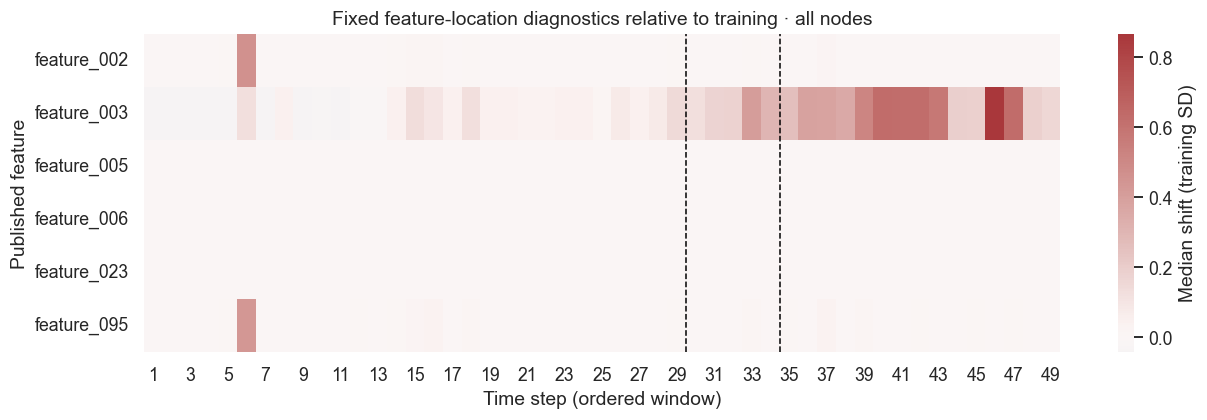

In [15]:
# Fixed label-free diagnostic; location and scale use training rows only.
shift_features = ["feature_002", "feature_003", "feature_005", "feature_006", "feature_023", "feature_095"]
training_median = training_nodes[shift_features].median()
training_scale = training_nodes[shift_features].std()
if (training_scale <= 0).any():
    raise ValueError("Shift diagnostic requires positive training standard deviations")
period_medians = nodes.groupby("time_step")[shift_features].median()
median_shift = (period_medians - training_median) / training_scale
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(median_shift.T, cmap="vlag", center=0, ax=ax,
            cbar_kws={"label": "Median shift (training SD)"})
for boundary in [29, 34]:
    ax.axvline(boundary, color="black", linewidth=1, linestyle="--")
ax.set(title="Fixed feature-location diagnostics relative to training · all nodes", xlabel="Time step (ordered window)", ylabel="Published feature")
save_figure(fig, "12_feature_location_shift")

**Interpretation:** The plotted value is `(snapshot median − training median) / training SD`. A location shift is only one aspect of covariate drift; equal medians do not imply equal distributions. The units use training standard deviations; this keeps features with zero training IQR interpretable without silently dropping them. No predictive preprocessing is fitted here. Post-hoc feature choices motivated by test-period diagnostics would compromise the final-test claim and require a new holdout.

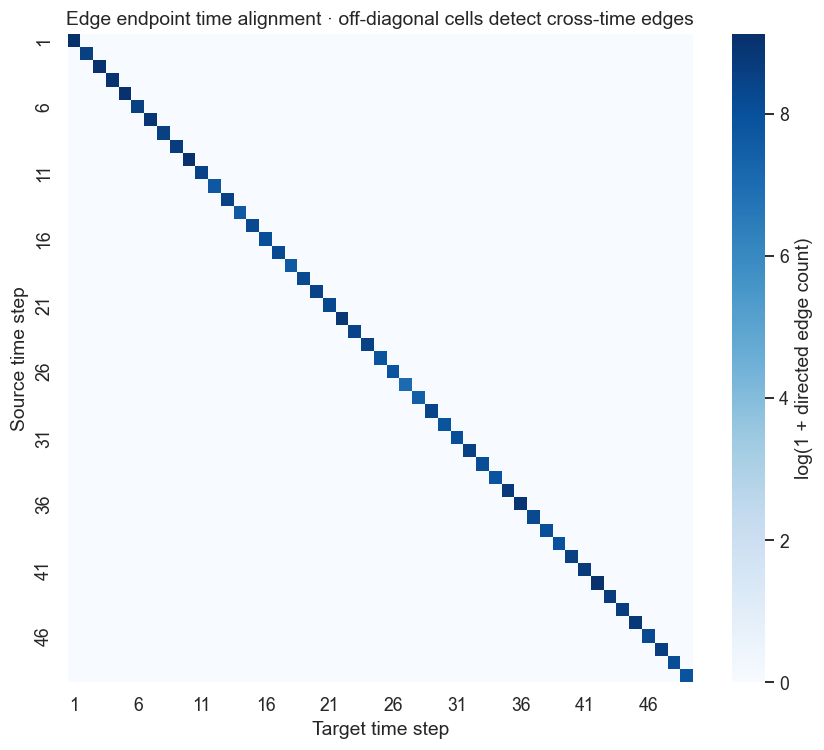

Cross-time edges: 0 | Backward-time edges: 0


In [16]:
edge_time_counts = pd.crosstab(edges.source_time, edges.target_time).reindex(index=range(1, 50), columns=range(1, 50), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(np.log1p(edge_time_counts), cmap="Blues", ax=ax,
            xticklabels=5, yticklabels=5, cbar_kws={"label": "log(1 + directed edge count)"})
ax.set(title="Edge endpoint time alignment · off-diagonal cells detect cross-time edges", xlabel="Target time step", ylabel="Source time step")
save_figure(fig, "13_edge_time_alignment")
print("Cross-time edges:", diagnostics["cross_time_edges"], "| Backward-time edges:", diagnostics["backward_time_edges"])

**Interpretation:** If the off-diagonal is empty, the published edge list supplies no inter-snapshot links. Temporal modeling must therefore justify how history informs later snapshots; the same transaction does not reappear with a persistent hidden state. Absence of cross-time edges does not rule out shared addresses, future-informed features, or source-level dependencies.

<a id="8-chronological-split"></a>
## 8. Chronological split

Fixed partitions are **training 1–29**, **validation 30–34**, and **test 35–49**, inclusive. There is no random train/test split. Later feature transformations and fitting use training information only; validation labels may score candidates or early stopping but must not enter fitting losses or preprocessing. Final-test labels are accessed only after methodology freeze.

Node membership and raw-file hashes are saved locally. No labels appear in the membership CSV. Snapshots are built at each prediction time; a graph containing every validation or test snapshot must not be reused to predict earlier snapshots.

class_name,licit,illicit,unknown,transactions,known_labels,illicit_prevalence_known,label_coverage
partition,,,,,,,
train,23510,2871,94423,120804,26381,0.1088,0.2184
validation,2922,591,11948,15461,3513,0.1682,0.2272
test,15587,1083,50834,67504,16670,0.0650,0.2469


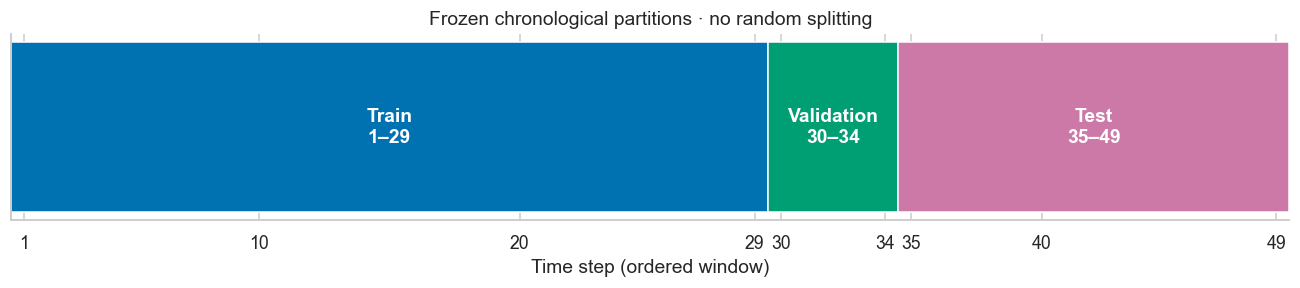

,cutoff,eligible_nodes,eligible_edges
0,1,7880,9164
28,29,120804,140223
29,30,123287,142784
33,34,136265,156843
34,35,141772,163194
48,49,203769,234355


Expected guard: Test targets sealed: freeze model selection before final evaluation


In [17]:
split_membership = save_split_definitions(nodes, PROCESSED_DIR, raw_hashes)
split_summary = pd.crosstab(partitions, nodes.class_name).reindex(index=["train", "validation", "test"], columns=["licit", "illicit", "unknown"], fill_value=0)
split_summary["transactions"] = split_summary[["licit", "illicit", "unknown"]].sum(axis=1)
split_summary["known_labels"] = split_summary.licit + split_summary.illicit
split_summary["illicit_prevalence_known"] = split_summary.illicit / split_summary.known_labels
split_summary["label_coverage"] = split_summary.known_labels / split_summary.transactions
display(split_summary.round(4))
split_summary.to_csv(RESULT_DIR / "split_summary.csv")

fig, ax = plt.subplots(figsize=(12, 2.8))
for name, (first, last) in SPLIT_RANGES.items():
    ax.barh(0, last - first + 1, left=first - 0.5, height=0.55, color=SPLIT_COLORS[name])
    ax.text((first + last) / 2, 0, f"{name.title()}\n{first}–{last}", ha="center", va="center", color="white", weight="bold")
ax.set(xlim=(0.5, 49.5), xlabel="Time step (ordered window)", title="Frozen chronological partitions · no random splitting", yticks=[])
ax.set_xticks([1, 10, 20, 29, 30, 34, 35, 40, 49])
ax.grid(axis="y", visible=False)
save_figure(fig, "14_chronological_partitions")

# Boundary audit; neither graph features nor arrays contain labels.
cutoff_checks = []
for cutoff in range(1, 50):
    graph_inputs = graph_at_step(nodes, edges, cutoff, group="transaction_sensitivity")
    assert (graph_inputs["time_step"] <= cutoff).all()
    for endpoint in graph_inputs["edge_index"]:
        assert (graph_inputs["time_step"][endpoint] <= cutoff).all()
    cutoff_checks.append({"cutoff": cutoff, "eligible_nodes": len(graph_inputs["x"]),
                          "eligible_edges": graph_inputs["edge_index"].shape[1]})
display(pd.DataFrame(cutoff_checks).iloc[[0, 28, 29, 33, 34, 48]])
try:
    supervised_targets(nodes, "test")
except PermissionError as error:
    print("Expected guard:", error)
else:
    raise AssertionError("Test-label access guard failed")

**Interpretation:** The partitions define a forecasting-style benchmark and different labeled prevalences. They do not create independent identically distributed observations. The local target guard reduces accidental test access but cannot undo Stage 1 summaries or prevent a researcher reading the public CSV.

<a id="9-leakage-audit"></a>
## 9. Leakage audit

Read [Šafář et al. (2026), DOI 10.1016/j.fsidi.2026.302124](https://doi.org/10.1016/j.fsidi.2026.302124) and its [public feature-semantics documentation](https://github.com/nesfit/DeanonymizedEllipticBitcoinDataset). The eight-page paper was read from the authors' university copy, including sections 3–6 and Figures 1–5. The detailed evidence, section pointers and source-access record are in `reports/leakage_audit.md`.

The paper reports dataset-wide normalization (section 4.1), future address histories (4.2), repeated addresses across splits (4.3), and truncated graph neighborhoods (4.4). Published aggregate features can include neighbors absent from the released edge list (3.2). These are source-reported findings, not independently reconstructed from raw Bitcoin data here.

**A — Benchmark:** compare algorithms on published inputs under a fixed chronological protocol. GNNs do not start with raw transaction information: tabular inputs already include neighborhood summaries.

**B — Conservative sensitivities:** compare all non-time features, local-only, and the fixed 18-feature transaction subset. Address-history features may contain later information even when called local. Removing aggregates is useful but insufficient.

**C — Unestablished claims:** leakage-free real-time detection, causal detection of illicit behavior, performance on unknown/unseen entities, availability of historical labels at training time, and deployable calibration. These require provenance, collection timestamps, or a reconstructed raw-chain dataset that this benchmark does not provide.

See also `reports/research_protocol.md` for the planned selection, final-test and inference rules. Stage 1 does not train or select models.

In [18]:
leakage_risks = pd.DataFrame([
    ["Future snapshot inputs", "Input construction audited at all 49 cutoffs", "Look-ahead bias", "Filter both endpoints and node rows at every prediction time; source feature provenance remains unresolved"],
    ["Dataset-wide normalization", "Paper section 4.1: normalization used the entire release", "Training inputs reflect held-out distribution statistics", "Train-only rescaling may cancel a pure affine transform; it cannot repair future histories or establish full provenance"],
    ["Address-history features", "Semantics documentation: features 23–94 use a fixed later reference block", "Local-only can remain future-informed", "Drop address-history group in sensitivity; cannot certify retained values"],
    ["Forward-neighbor aggregates", "Published group 95–166 summarizes incoming/outgoing transaction neighbors", "Graph signal is already embedded in tabular inputs", "Report published and conservative groups on the same labeled nodes"],
    ["Shared-address dependence", "Paper section 4.3: address signals and labels recur across partitions", "Unseen-entity generalization is untested", "No address-disjointness audit possible from released IDs and edges alone"],
    ["Truncated neighborhoods", "Paper sections 3.2 and 4.4: aggregates include neighbors outside the released graph", "Tabular and GNN inputs describe different scopes", "Separate feature groups; do not claim gains reflect access to equivalent raw information"],
    ["Cross-time released edges", f"Observed {diagnostics['cross_time_edges']} cross-time edges", "Later nodes can contaminate earlier graphs if present", "Cutoff graph builder; zero cross-time edges does not certify feature cleanliness"],
    ["Unknown-label selection", f"Observed {diagnostics['unknown_percentage']:.2f}% unknown", "Known-label metrics may not generalize", "Unknown excluded from supervision; eligible unknown nodes allowed in message passing"],
    ["Test EDA exposure", "Stage 1 requested class summaries for all periods", "Researcher decisions can adapt to the holdout", "Record exposure; freeze methodology before predictive test evaluation"],
    ["Label timing", "Publication labels have no acquisition timestamps", "Training labels may not be historically available", "Retrospective benchmark only; no operational label-latency claim"],
], columns=["Risk", "Evidence", "Impact", "Mitigation / limitation"])
with pd.option_context("display.max_colwidth", 110):
    display(leakage_risks)
leakage_risks.to_csv(RESULT_DIR / "leakage_risks.csv", index=False)

,Risk,Evidence,Impact,Mitigation / limitation
0,Future snapshot inputs,Input construction audited at all 49 cutoffs,Look-ahead bias,Filter both endpoints and node rows at every prediction time; source feature provenance remains unresolved
1,Dataset-wide normalization,Paper section 4.1: normalization used the entire release,Training inputs reflect held-out distribution statistics,Train-only rescaling may cancel a pure affine transform; it cannot repair future histories or establish fu...
2,Address-history features,Semantics documentation: features 23–94 use a fixed later reference block,Local-only can remain future-informed,Drop address-history group in sensitivity; cannot certify retained values
3,Forward-neighbor aggregates,Published group 95–166 summarizes incoming/outgoing transaction neighbors,Graph signal is already embedded in tabular inputs,Report published and conservative groups on the same labeled nodes
4,Shared-address dependence,Paper section 4.3: address signals and labels recur across partitions,Unseen-entity generalization is untested,No address-disjointness audit possible from released IDs and edges alone
5,Truncated neighborhoods,Paper sections 3.2 and 4.4: aggregates include neighbors outside the released graph,Tabular and GNN inputs describe different scopes,Separate feature groups; do not claim gains reflect access to equivalent raw information
6,Cross-time released edges,Observed 0 cross-time edges,Later nodes can contaminate earlier graphs if present,Cutoff graph builder; zero cross-time edges does not certify feature cleanliness
7,Unknown-label selection,Observed 77.15% unknown,Known-label metrics may not generalize,Unknown excluded from supervision; eligible unknown nodes allowed in message passing
8,Test EDA exposure,Stage 1 requested class summaries for all periods,Researcher decisions can adapt to the holdout,Record exposure; freeze methodology before predictive test evaluation
9,Label timing,Publication labels have no acquisition timestamps,Training labels may not be historically available,Retrospective benchmark only; no operational label-latency claim


**Availability rule:** We approximate an edge's arrival by the later endpoint time because no edge acquisition time is published. At snapshot end, same-snapshot edges are eligible by assumption. Unknown labels are never propagated as label features. Reverse edges, normalization and structural-feature calculations must occur only after temporal filtering. None of these operations reconstructs the information vintage of the supplied numeric features.

<a id="10-key-findings"></a>
## 10. Key findings

The following summary is computed from the loaded files. No predictive performance numbers are produced in Stage 1. A successful notebook establishes reproducible file handling and descriptive analysis, not validity of a trained detector.

In [19]:
summary_lines = [
    f"- Validated **{len(nodes):,} transactions**, **{len(edges):,} edges**, **{nodes.time_step.nunique()} time steps** and **166 published features including time**.",
    f"- **{diagnostics['illicit']:,} illicit**, **{diagnostics['licit']:,} licit**, **{diagnostics['unknown']:,} unknown**; unknown share **{diagnostics['unknown_percentage']:.2f}%**.",
    f"- Missing feature values: **{diagnostics['missing_feature_values']}**. Duplicate feature vectors across distinct IDs: **{diagnostics['duplicate_feature_vectors']}**; nodes retained.",
    f"- Cross-time released edges: **{diagnostics['cross_time_edges']}**. Weak components: **{weak_count:,}**. This does not establish source-level split isolation.",
    "- Fixed chronological memberships were saved locally without targets; every cutoff passed a no-future-input audit.",
    f"- **{len(figure_names)} analytical figures** saved as 300 dpi PNG and SVG and displayed inline.",
    "- Published-feature benchmark and conservative sensitivities remain necessary; local-only is not automatically leakage-free.",
    "- Exploration and chronological split preparation completed. Model training followed in subsequent stages.",
]
if QUICK_RUN:
    summary_lines.insert(0, "**QUICK_RUN — exploratory diagnostic sampling; not final research evidence.**")
display(Markdown("\n".join(summary_lines)))

config = {
    "stage": 1, "run_mode": RUN_MODE, "exploratory": QUICK_RUN, "seed": SEED,
    "dataset": "original Elliptic; user-supplied Kaggle archive",
    "data_directory_configuration": "ELLIPTIC_DATA_DIR or data/raw; local path not persisted",
    "raw_sha256": raw_hashes, "split_ranges_inclusive": SPLIT_RANGES,
    "plot_sample_per_class": PLOT_SAMPLE, "correlation_sample": CORRELATION_SAMPLE,
    "feature_groups": groups, "selected_features": selected_features,
    "feature_provenance": "unresolved; no fully leakage-free claim",
    "seconds": round(time.perf_counter() - started_at, 3),
    "figures": figure_names, "cutoff_checks_passed": len(cutoff_checks),
    "model_training_performed": False,
    "numeric_feature_policy": "reject_missing_and_infinite_without_imputation",
    "comparison_feature_groups": ["transaction_sensitivity", "local_without_time", "published_without_time"],
}
(RESULT_DIR / "stage1_config.json").write_text(json.dumps(config, indent=2) + "\n")
(RESULT_DIR / "connectivity.json").write_text(json.dumps(component_summary, indent=2) + "\n")
# Aggregate tables only; no transaction-level data exported to tracked locations.
snapshots.to_csv(RESULT_DIR / "snapshot_summary.csv")
quality_table.to_csv(RESULT_DIR / "quality_summary.csv", index=False)
feature_statistics.to_csv(RESULT_DIR / "training_feature_statistics.csv")
print(f"Stage 1 runtime: {config['seconds']:.1f} seconds.")

- Validated **203,769 transactions**, **234,355 edges**, **49 time steps** and **166 published features including time**.
- **4,545 illicit**, **42,019 licit**, **157,205 unknown**; unknown share **77.15%**.
- Missing feature values: **0**. Duplicate feature vectors across distinct IDs: **34**; nodes retained.
- Cross-time released edges: **0**. Weak components: **49**. This does not establish source-level split isolation.
- Fixed chronological memberships were saved locally without targets; every cutoff passed a no-future-input audit.
- **13 analytical figures** saved as 300 dpi PNG and SVG and displayed inline.
- Published-feature benchmark and conservative sensitivities remain necessary; local-only is not automatically leakage-free.
- Exploration and chronological split preparation completed. Model training followed in subsequent stages.

Stage 1 runtime: 12.3 seconds.


### References and attribution

- Elliptic, original [Elliptic Data Set](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set), CC BY-NC-ND 4.0. [Elliptic](https://www.elliptic.co/).
- Weber, M., Domeniconi, G., Chen, J., Weidele, D. K. I., Bellei, C., Robinson, T., & Leiserson, C. E. (2019). *Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics*. [arXiv:1908.02591](https://arxiv.org/abs/1908.02591).
- Šafář, M., Pluskal, J., Veselý, V., & Ryšavý, O. (2026). *The enemy of reproducibility is opacity: What's inside the Elliptic bitcoin dataset (and why it is wrong).* Forensic Science International: Digital Investigation, 57, 302124. [DOI](https://doi.org/10.1016/j.fsidi.2026.302124); [public semantics](https://github.com/nesfit/DeanonymizedEllipticBitcoinDataset).
- [PyTorch MPS documentation](https://docs.pytorch.org/docs/stable/notes/mps.html); [PyG installation](https://pytorch-geometric.readthedocs.io/en/latest/notes/installation.html); [original-dataset loader source](https://pytorch-geometric.readthedocs.io/en/latest/_modules/torch_geometric/datasets/elliptic.html).